# 04 · Hiperparametre Karşılaştırması

**Amaç:** 03'teki temel modelin ayarlarını tek tek değiştirip hangisinin doğrulama sonucunu iyileştirdiğini görmek.

| Bölüm | Ne yapılıyor? |
|---|---|
| 1. Kurulum | GPU kontrolü, temel ayarlar |
| 2. Veriyi yükleme | Eğitim ve doğrulama kümeleri |
| 3. Denemeler | Hangi ayar neye değiştiriliyor? |
| 4. Eğitim | Bütün denemeler sırayla eğitilir |
| 5. Karşılaştırma tablosu | Doğrulama ölçütleri, temel modelden fark |
| 6. Öğrenme eğrileri | Gruplara göre doğrulama PR-AUC'si |
| 7. Kategoriye göre sonuçlar | EF'ye göre yakalama, WRN / NUL yanlış alarm |
| 8. En iyi ayarların birleşimi | 3 farklı seed ile son model |

**Çalışma zamanı:** **T4 GPU**. 15 deneme toplam yaklaşık 2 saat. Colab koparsa ya da kota biterse 4. bölümdeki hücreyi tekrar çalıştır: bitmiş denemeler atlanır, yarım kalan kaldığı turdan devam eder.

Bütün ölçütler doğrulama kümesinde. Test kümesi kullanılmıyor.

**Seçim ölçütü doğrulama PR-AUC'sidir** (karar H3, `reports/kararlar.md`). Veride yalnızca %8 hortum var; ROC-AUC çok sayıdaki doğru red yüzünden yüksek görünebilir, PR-AUC ise hortum sınıfına odaklanır. En iyi tur ve erken durdurma da aynı ölçüte göre (karar O1).

In [5]:
# --- Kurulum: hem Google Colab'da hem kendi bilgisayarında çalışır ---
import os, sys
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")                     # işlenmiş veri Drive'da saklanır
    REPO = Path("/content/tornado-cnn")
    if not REPO.exists():
        try:                                          # repo private ise: Colab Secrets'taki token
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:                             # repo public ise token gerekmez
            token = ""
        !git clone -q https://{token}github.com/baevv/tornado-cnn.git {REPO}
    else:
        !git -C {REPO} pull -q
    %pip install -q h5netcdf h5py
    os.chdir(REPO)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(REPO))
# src/ klasöründen daha önce yüklenmiş kodu bellekten sil: git pull ile gelen yeni kod
# bir sonraki import'ta kullanılsın (oturumu yeniden başlatmaya gerek kalmasın).
for _m in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]

print("Colab" if IN_COLAB else "Yerel", "| repo:", REPO)

Mounted at /content/drive
Colab | repo: /content/tornado-cnn


## 1. Kurulum

Temel ayarlar 03'teki gibi `configs/train.json` dosyasından okunuyor.

In [6]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from src.helper import paths, train
from src.helper import model as cnn

cfg_data = paths.load_config()
with open(REPO / "configs" / "train.json") as f:
    BASE = json.load(f)

device = train.get_device()
if device.type == "cuda":
    print("cihaz: GPU |", torch.cuda.get_device_name(0))
else:
    print("UYARI: GPU yok, eğitim çok yavaş olur. Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU")
BASE

cihaz: GPU | Tesla T4


{'batch_size': 64,
 'optimizer': 'adam',
 'lr': 0.001,
 'weight_decay': 0.0,
 'epochs': 20,
 'patience': 4,
 'dropout': 0.3,
 'weighting': 'pos_weight',
 'monitor': 'pr_auc',
 'augment': False,
 'label_smoothing': 0.0,
 'seed': 42,
 'num_workers': 2}

## 2. Veriyi yükleme

03'teki gibi. `HIZLI_DENEME = True` sadece kodu denemek içindir (2017 verisi, her deneme 2 tur).

In [7]:
HIZLI_DENEME = False

years = [2017] if HIZLI_DENEME else cfg_data["years"]
splits = train.load_splits(paths.data_dir())
local_dir = Path("/content/data_local") if IN_COLAB else None
data, variables = train.load_data(paths.processed_dir(), splits, years, which=("train", "val"), local_dir=local_dir)

y_val, meta_val = data["val"]["y"], data["val"]["meta"]
n_pos = int(data["train"]["y"].sum())
n_neg = len(data["train"]["y"]) - n_pos
ratio = n_neg / n_pos
print(f"eğitim {len(data['train']['y']):,} örnek ({n_pos:,} hortum) | doğrulama {len(y_val):,} örnek ({int(y_val.sum()):,} hortum)")
print(f"hortumsuz / hortum = {ratio:.2f}")

eğitim 48,703 örnek (3,786 hortum) | doğrulama 8,040 örnek (690 hortum)
hortumsuz / hortum = 11.86


## 3. Denemeler

Her denemede **tek bir ayar** değişiyor, diğerleri temel modeldeki gibi kalıyor.

* **Temel model** 03'te eğitilen model. Yeniden eğitilmiyor, Drive'dan yükleniyor.
* Diğer denemelerde en fazla tur sayısı 30 (temelde 20). Düşük öğrenme oranıyla model daha yavaş öğrendiği için. Temel model 13. turda durduğu için bu farkı etkilemiyor.
* **Planlamalı lr:** Doğrulama PR-AUC'si 2 tur iyileşmezse öğrenme oranı yarıya iner. Azalan oranın etkisini görebilmek için erken durdurma sabrı 6.
* **`pos_weight` karekök:** √(hortumsuz / hortum), tam eşitleme (11,71) ile ağırlıksız (1) arası.

**Optimizer:** Adam = momentum + ağırlık başına uyarlanan öğrenme oranı (RMSprop). Denemeler bu iki parçanın katkısını ayırıyor:

| | Ağırlık başına lr yok | Ağırlık başına lr var |
|---|---|---|
| **Momentum yok** | SGD | RMSprop |
| **Momentum var** | SGD + momentum | Adam (temel) |

SGD ve SGD + momentum daha büyük öğrenme oranı ister (0,01). RMSprop, Adam ile aynı lr'yi (0,001) kullanır.

In [8]:
EXPERIMENTS = [
    # (grup, ad, temel ayarlardan farkı)
    ("Temel model",     "temel",        {}),
    ("Öğrenme oranı",   "lr_0.0003",    {"lr": 0.0003}),
    ("Öğrenme oranı",   "lr_0.0001",    {"lr": 0.0001}),
    ("Öğrenme oranı",   "lr_planlama",  {"scheduler": "plateau", "patience": 6}),
    ("Düzenlileştirme", "l2_0.0001",    {"weight_decay": 0.0001}),
    ("Düzenlileştirme", "l2_0.001",     {"weight_decay": 0.001}),
    ("Düzenlileştirme", "dropout_0",    {"dropout": 0.0}),
    ("Düzenlileştirme", "dropout_0.5",  {"dropout": 0.5}),
    ("Model boyutu",    "genis_model",  {"filters": [32, 64, 128, 256]}),
    ("Batch boyutu",    "batch_32",     {"batch_size": 32}),
    ("Batch boyutu",    "batch_128",    {"batch_size": 128}),
    ("Optimizer",       "sgd",          {"optimizer": "sgd", "lr": 0.01}),
    ("Optimizer",       "sgd_momentum", {"optimizer": "momentum", "lr": 0.01}),
    ("Optimizer",       "rmsprop",      {"optimizer": "rmsprop"}),
    ("Kayıp ağırlığı",  "pw_1",         {"pos_weight": 1.0}),
    ("Kayıp ağırlığı",  "pw_karekok",   {"pos_weight": round(ratio ** 0.5, 2)}),
]
GROUP = {name: group for group, name, _ in EXPERIMENTS}
CHANGE = {name: ", ".join(f"{k} = {v}" for k, v in ov.items()) or "—" for _, name, ov in EXPERIMENTS}
pd.DataFrame({"grup": GROUP, "değişiklik": CHANGE})

,grup,değişiklik
temel,Temel model,—
lr_0.0003,Öğrenme oranı,lr = 0.0003
lr_0.0001,Öğrenme oranı,lr = 0.0001
lr_planlama,Öğrenme oranı,"scheduler = plateau, patience = 6"
l2_0.0001,Düzenlileştirme,weight_decay = 0.0001
l2_0.001,Düzenlileştirme,weight_decay = 0.001
dropout_0,Düzenlileştirme,dropout = 0.0
dropout_0.5,Düzenlileştirme,dropout = 0.5
genis_model,Model boyutu,"filters = [32, 64, 128, 256]"
batch_32,Batch boyutu,batch_size = 32


## 4. Eğitim

Her deneme Drive'da kendi klasörüne kaydedilir (`tornado-cnn/models/04_<ad>/`). Her deneme için eşik 03'teki gibi doğrulamada F1'e göre seçilir.

In [9]:
def run(name, overrides, seed=None):
    """Bir denemeyi eğitir (ya da kayıttan yükler) ve doğrulama sonuçlarını döndürür."""
    cfg = dict(BASE) if name == "temel" else {**BASE, "epochs": 30, **overrides}
    if seed is not None:
        cfg["seed"] = seed
    if HIZLI_DENEME:
        cfg["epochs"] = 2
    folder = "03_baseline" if name == "temel" else f"04_{name}"
    out = paths.models_dir(folder + ("_hizli" if HIZLI_DENEME else ""))

    train.set_seed(cfg["seed"])
    w_train, pos_weight = train.class_weights(data["train"]["meta"], cfg["weighting"])
    pos_weight = cfg.get("pos_weight", pos_weight)
    train_loader, val_loader = train.make_loaders(data, cfg, w_train)
    net = cnn.TornadoCNN(in_channels=len(variables), filters=tuple(cfg.get("filters", (16, 32, 64, 128))),
                         dropout=cfg["dropout"]).to(device)
    history = train.fit(net, train_loader, val_loader, cfg, variables, out, pos_weight, device)

    p_val, _ = train.predict(net, val_loader, variables, device, pos_weight)
    threshold = train.choose_threshold(y_val, p_val)
    res = {**train.metrics(y_val, p_val, threshold), "eşik": threshold,
           "en iyi tur": train.best_epoch(history, cfg), "tur sayısı": len(history),
           "süre (dk)": history["süre (sn)"].sum() / 60, "parametre": cnn.count_params(net),
           **train.breakdown(meta_val, p_val, threshold)}
    if name != "temel":                                    # 03'ün kayıtlarına dokunulmaz
        train.save_results(out, config=cfg, pos_weight=pos_weight, validation=res)
    del net
    torch.cuda.empty_cache()
    return res, history


results, histories = {}, {}
for group, name, overrides in EXPERIMENTS:
    print(f"\n=== {group} · {name} · {CHANGE[name]} ===")
    results[name], histories[name] = run(name, overrides)


=== Temel model · temel · — ===
Kayıt bulundu: 9. turdan devam ediliyor.
En iyi tur: 5 (doğrulama PR-AUC 0.5843). Bu turun ağırlıkları yüklendi.

=== Öğrenme oranı · lr_0.0003 · lr = 0.0003 ===
Kayıt bulundu: 11. turdan devam ediliyor.
En iyi tur: 7 (doğrulama PR-AUC 0.5577). Bu turun ağırlıkları yüklendi.

=== Öğrenme oranı · lr_0.0001 · lr = 0.0001 ===
Kayıt bulundu: 19. turdan devam ediliyor.
En iyi tur: 15 (doğrulama PR-AUC 0.5202). Bu turun ağırlıkları yüklendi.

=== Öğrenme oranı · lr_planlama · scheduler = plateau, patience = 6 ===
Kayıt bulundu: 12. turdan devam ediliyor.
En iyi tur: 6 (doğrulama PR-AUC 0.5777). Bu turun ağırlıkları yüklendi.

=== Düzenlileştirme · l2_0.0001 · weight_decay = 0.0001 ===
Kayıt bulundu: 14. turdan devam ediliyor.
En iyi tur: 10 (doğrulama PR-AUC 0.5850). Bu turun ağırlıkları yüklendi.

=== Düzenlileştirme · l2_0.001 · weight_decay = 0.001 ===
Kayıt bulundu: 11. turdan devam ediliyor.
En iyi tur: 7 (doğrulama PR-AUC 0.6003). Bu turun ağırlıkları y

## 5. Karşılaştırma tablosu

* **Δ PR-AUC:** temel modele göre fark (seçim ölçütü, karar H3). Tablo bu sütuna göre büyükten küçüğe sıralı.
* **Gürültü sınırı ±0,02** (karar H2): doğrulama ölçütleri turdan tura bu kadar oynuyor. Farkı bunu açıkça aşmayan ayar "etkili" sayılmaz.
* **Karar kuralı (H2):** Gürültüyü aşan en fazla 2 ayar (A ve B) çıkarsa 8. bölümde ikisi birlikte denenir. Böylece 2 × 2 ızgara tamamlanır: temel, yalnız A ve yalnız B hücreleri bu tabloda zaten var, eksik olan tek hücre A + B. Hiçbir ayar gürültüyü aşmazsa varsayılan ayarlar korunur.
* Her satırın eşiği kendi doğrulama sonucuna göre seçildi.

In [10]:
METRICS = ["ROC-AUC", "PR-AUC", "F1", "recall (yakalama)", "precision (isabet)", "eşik",
           "en iyi tur", "tur sayısı", "süre (dk)", "parametre"]
table = pd.DataFrame(results).T[METRICS].astype(float)
table.insert(0, "değişiklik", pd.Series(CHANGE))
table.insert(0, "grup", pd.Series(GROUP))
table.insert(3, "Δ PR-AUC", table["PR-AUC"] - table.loc["temel", "PR-AUC"])
table = table.sort_values("Δ PR-AUC", ascending=False)
table[["en iyi tur", "tur sayısı", "parametre"]] = table[["en iyi tur", "tur sayısı", "parametre"]].astype(int)
table.round(3)

,grup,değişiklik,ROC-AUC,Δ PR-AUC,PR-AUC,F1,recall (yakalama),precision (isabet),eşik,en iyi tur,tur sayısı,süre (dk),parametre
l2_0.001,Düzenlileştirme,weight_decay = 0.001,0.891,0.016,0.600,0.578,0.561,0.596,0.888,7,11,5.262,105761
batch_128,Batch boyutu,batch_size = 128,0.888,0.013,0.597,0.565,0.610,0.527,0.871,7,11,5.239,105761
sgd_momentum,Optimizer,"optimizer = momentum, lr = 0.01",0.886,0.009,0.593,0.576,0.593,0.560,0.513,7,11,5.393,105761
rmsprop,Optimizer,optimizer = rmsprop,0.880,0.001,0.585,0.566,0.597,0.538,0.773,6,10,4.879,105761
l2_0.0001,Düzenlileştirme,weight_decay = 0.0001,0.866,0.001,0.585,0.562,0.562,0.561,0.771,10,14,6.741,105761
temel,Temel model,—,0.882,0.000,0.584,0.570,0.574,0.567,0.731,5,9,4.192,105761
dropout_0.5,Düzenlileştirme,dropout = 0.5,0.883,-0.003,0.581,0.551,0.613,0.501,0.759,9,13,6.180,105761
genis_model,Model boyutu,"filters = [32, 64, 128, 256]",0.892,-0.005,0.580,0.564,0.583,0.546,0.888,2,6,5.512,404929
pw_1,Kayıp ağırlığı,pos_weight = 1.0,0.883,-0.005,0.580,0.561,0.559,0.564,0.317,5,9,4.429,105761
batch_32,Batch boyutu,batch_size = 32,0.885,-0.005,0.579,0.568,0.626,0.520,0.818,5,9,4.673,105761


## 6. Öğrenme eğrileri

Her grafikte bir grubun denemeleri. Kesikli siyah çizgi temel model.

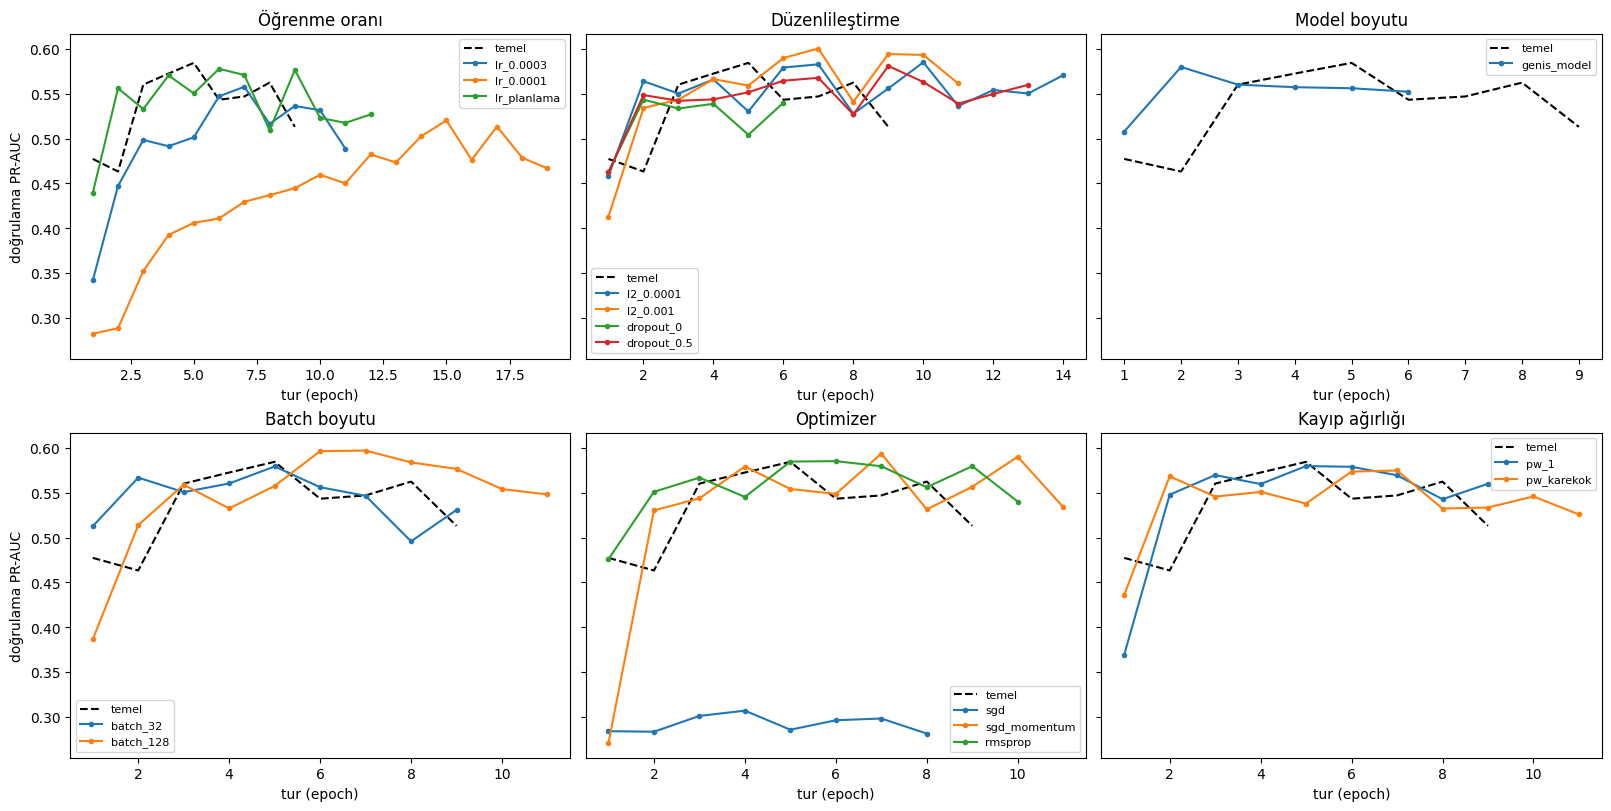

In [11]:
groups = [g for g in dict.fromkeys(GROUP.values()) if g != "Temel model"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout="constrained", sharey=True)
for ax, g in zip(axes.flat, groups):
    h = histories["temel"]
    ax.plot(h["tur"], h["doğrulama PR-AUC"], "k--", label="temel")
    for name in [n for n, gr in GROUP.items() if gr == g]:
        h = histories[name]
        ax.plot(h["tur"], h["doğrulama PR-AUC"], "o-", ms=3, label=name)
    ax.set_title(g)
    ax.set_xlabel("tur (epoch)")
    ax.legend(fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("doğrulama PR-AUC")
plt.show()

## 7. Kategoriye göre sonuçlar

Her denemenin seçilen eşiğinde:

* **EF0–1 / EF2+ yakalama:** bu şiddetteki hortumların yüzde kaçı bulundu?
* **WRN / NUL yanlış alarm:** uyarı fırtınalarının ve sıradan fırtınaların yüzde kaçına "hortum" denildi?

Kayıp ağırlığı ve eşik özellikle bu dengeyi değiştirir.

In [12]:
BREAK = ["EF0–1 yakalama", "EF2+ yakalama", "WRN yanlış alarm", "NUL yanlış alarm"]
counts = {"EF0–1 yakalama": ((meta_val.category == "TOR") & (meta_val.ef_number < 2)).sum(),
          "EF2+ yakalama": ((meta_val.category == "TOR") & (meta_val.ef_number >= 2)).sum(),
          "WRN yanlış alarm": (meta_val.category == "WRN").sum(),
          "NUL yanlış alarm": (meta_val.category == "NUL").sum()}
print("doğrulamadaki örnek sayıları:", {k: int(v) for k, v in counts.items()})
cat_table = pd.DataFrame(results).T[BREAK].astype(float)
cat_table.insert(0, "grup", pd.Series(GROUP))
cat_table.round(3)

doğrulamadaki örnek sayıları: {'EF0–1 yakalama': 541, 'EF2+ yakalama': 149, 'WRN yanlış alarm': 2717, 'NUL yanlış alarm': 4633}


,grup,EF0–1 yakalama,EF2+ yakalama,WRN yanlış alarm,NUL yanlış alarm
temel,Temel model,0.551,0.658,0.088,0.014
lr_0.0003,Öğrenme oranı,0.536,0.705,0.103,0.010
lr_0.0001,Öğrenme oranı,0.481,0.678,0.098,0.013
lr_planlama,Öğrenme oranı,0.560,0.658,0.096,0.013
l2_0.0001,Düzenlileştirme,0.536,0.658,0.097,0.009
l2_0.001,Düzenlileştirme,0.514,0.732,0.085,0.007
dropout_0,Düzenlileştirme,0.503,0.705,0.099,0.010
dropout_0.5,Düzenlileştirme,0.582,0.725,0.128,0.016
genis_model,Model boyutu,0.536,0.752,0.106,0.010
batch_32,Batch boyutu,0.603,0.711,0.123,0.014


## 8. En iyi ayarların birleşimi

5. bölümdeki tabloya bakıp PR-AUC'yi **gürültü sınırını (±0,02) açıkça aşacak şekilde iyileştiren** en fazla 2 ayarı `BEST` içine yaz (ör. `{"lr": 0.0003, "weight_decay": 0.0001}`) ve bu hücreyi çalıştır. Hiçbir ayar gürültüyü aşmıyorsa `BEST` boş kalır ve varsayılan ayarlar korunur (karar H2). Model, sonucun şans olmadığını görmek için 3 farklı seed ile eğitilir; sonuç ortalama ± std olarak verilir (karar H4). Seçilen model 06 (test) ve 07'de (Grad-CAM) kullanılacak.

In [13]:
BEST = {}          # 1. aşamanın sonucuna göre doldur
SEEDS = [42, 7, 123]   # karar H4: 3 seed

if not BEST:
    print("BEST boş: önce 5. bölümdeki tabloyu incele.")
else:
    final, final_hist = {}, {}
    for s in SEEDS:
        print(f"\n=== birleşim · seed {s} · {BEST} ===")
        final[f"seed {s}"], final_hist[s] = run(f"final_s{s}", BEST, seed=s)
    final_table = pd.DataFrame({"temel": results["temel"], **final}).T[METRICS + BREAK].astype(float)
    display(final_table.round(3))
    seed_rows = final_table.drop(index="temel")
    print("3 seed ortalama ± std:")
    display(pd.DataFrame({"ortalama": seed_rows.mean(), "std": seed_rows.std()}).loc[["PR-AUC", "ROC-AUC", "F1", "eşik"]].round(4))

BEST boş: önce 5. bölümdeki tabloyu incele.


## Kaydetme

Karşılaştırma tabloları Drive'a (`tornado-cnn/models/04_ozet/`) kaydedilir. Modeller zaten her denemenin kendi klasöründe.

In [14]:
summary_dir = paths.models_dir("04_ozet" + ("_hizli" if HIZLI_DENEME else ""))
summary_dir.mkdir(parents=True, exist_ok=True)
table.to_csv(summary_dir / "karsilastirma.csv")
cat_table.to_csv(summary_dir / "kategoriler.csv")
if BEST:
    final_table.to_csv(summary_dir / "birlesim.csv")
    with open(summary_dir / "best.json", "w") as f:
        json.dump(BEST, f, indent=1)
for f in sorted(summary_dir.iterdir()):
    print(f.name)

karsilastirma.csv
kategoriler.csv
